<a href="https://colab.research.google.com/github/miriamamin1213-ux/AUC_Curves/blob/main/HancockGPT2TabSHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda
Mounted at /content/drive
Rows with known target: 332
Class counts: {0: 191, 1: 141}
Train 215 {0: 123, 1: 92}
Validation 50 {0: 29, 1: 21}
Test 67 {0: 39, 1: 28}
Encoded input dimension: 19
Class weights: [0.87398374 1.16847826]


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Other trainable parameters: 116354


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:910.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | train=0.5863 | val=0.6013 | ROC-AUC=0.7365 | PR-AUC=0.6538 | balanced accuracy=0.7151
Epoch 100/500 | train=0.4848 | val=0.5845 | ROC-AUC=0.7496 | PR-AUC=0.7465 | balanced accuracy=0.7471
Epoch 150/500 | train=0.4495 | val=0.5636 | ROC-AUC=0.7709 | PR-AUC=0.7528 | balanced accuracy=0.7389
Epoch 200/500 | train=0.4240 | val=0.6416 | ROC-AUC=0.7611 | PR-AUC=0.7347 | balanced accuracy=0.7430
Epoch 250/500 | train=0.3491 | val=0.9603 | ROC-AUC=0.6954 | PR-AUC=0.6668 | balanced accuracy=0.6823
Epoch 300/500 | train=0.3286 | val=1.1056 | ROC-AUC=0.6708 | PR-AUC=0.6589 | balanced accuracy=0.6691
Epoch 350/500 | train=0.2710 | val=1.3958 | ROC-AUC=0.6773 | PR-AUC=0.6505 | balanced accuracy=0.6782
Epoch 400/500 | train=0.2525 | val=1.6540 | ROC-AUC=0.6379 | PR-AUC=0.5966 | balanced accuracy=0.6281
Epoch 450/500 | train=0.2430 | val=1.8618 | ROC-AUC=0.6149 | PR-AUC=0.5878 | balanced accuracy=0.6412
Epoch 500/500 | train=0.1826 | val=2.2067 | ROC-AUC=0.6232 | PR-AUC=0.5697 | balanc

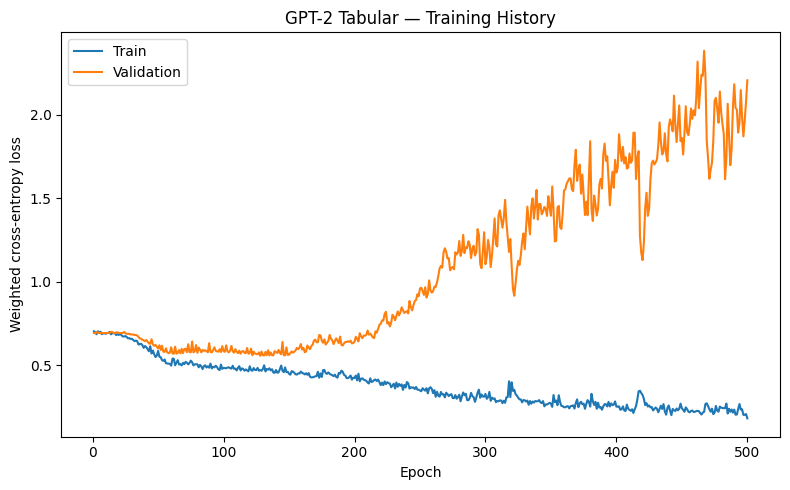


CHECKPOINT: best_val_loss | Epoch: 128
Checkpoint                      best_val_loss
Epoch                                     128
Threshold                            0.345092
Validation_Loss                      0.557112
Validation_ROC_AUC                   0.779146
Validation_PR_AUC                    0.754429
Validation_Balanced_Accuracy         0.773399
Balanced_Accuracy                    0.731227
F1                                   0.707692
ROC_AUC                              0.807692
PR_AUC                               0.782279
Confusion matrix:
 [[25 14]
 [ 5 23]]
              precision    recall  f1-score   support

HPV Negative     0.8333    0.6410    0.7246        39
HPV Positive     0.6216    0.8214    0.7077        28

    accuracy                         0.7164        67
   macro avg     0.7275    0.7312    0.7162        67
weighted avg     0.7449    0.7164    0.7176        67


CHECKPOINT: best_val_roc_auc | Epoch: 148
Checkpoint                      best_val_roc_a

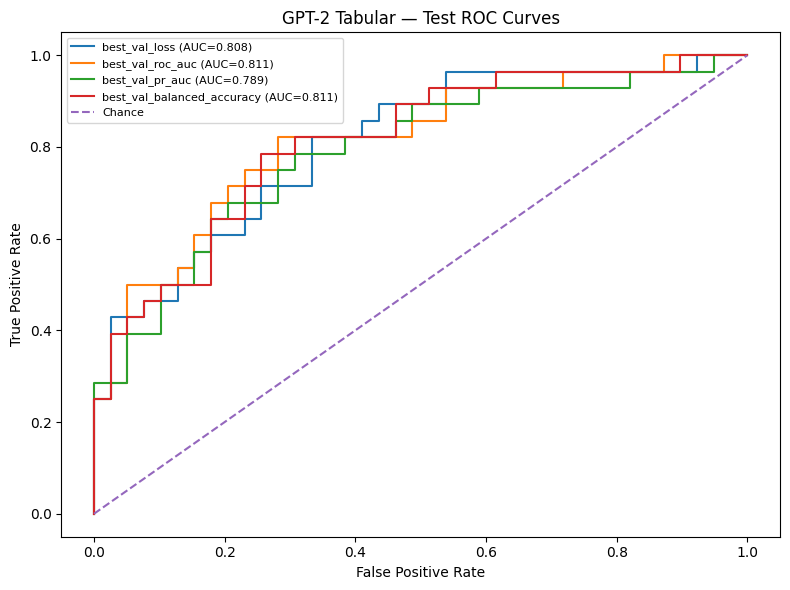

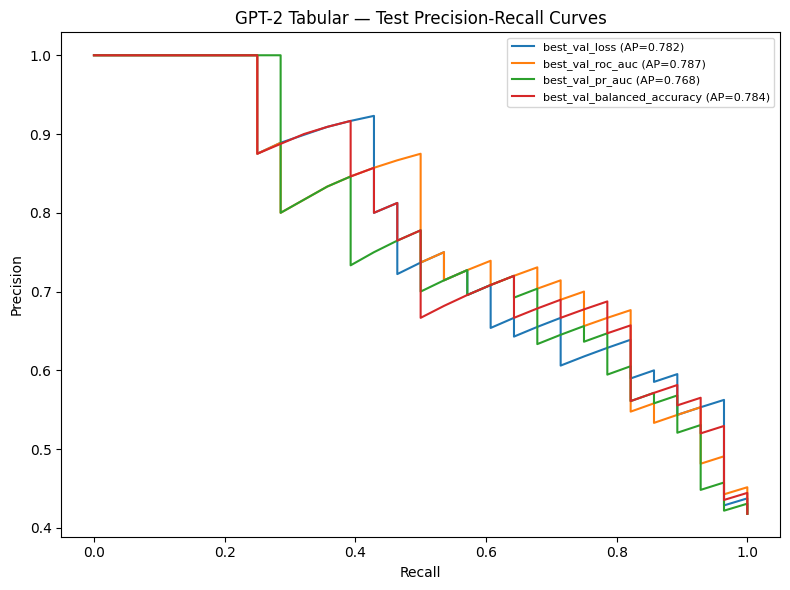

All results saved to: /content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results
Files: ['HANCOCK_GPT2_Tabular_Frozen_confidence_intervals.csv', 'HANCOCK_GPT2_Tabular_ROC_AUC_Summary.csv', 'HANCOCK_GPT2_Tabular_ROC_CI.csv', 'HANCOCK_GPT2_Tabular_ROC_Curve_CI.png', 'HANCOCK_GPT2_Tabular_Test_PR_Curve.png', 'HANCOCK_GPT2_Tabular_Test_ROC_Curve.png', 'HANCOCK_LIME_Feature_Importance.csv', 'HANCOCK_LIME_Feature_Importance.png', 'HANCOCK_LIME_Patient_Results.csv', 'HANCOCK_SHAP_Beeswarm.png', 'HANCOCK_SHAP_Feature_Importance.csv', 'SHAP_LIME_Epoch148', 'checkpoints', 'metrics_all_checkpoints.csv', 'run_summary.json', 'tabular_preprocessor.joblib', 'test_pr_curves.png', 'test_predictions_all_checkpoints.csv', 'test_roc_curves.png', 'training_history.csv', 'training_history.png']


In [1]:

# HANCOCK HPV — GPT-2 TABULAR CLASSIFIER
# Matched protocol: clinical narrative reference
# 65/15/20 stratified split | Seed 42 | Batch 64 | 500 epochs
# No SMOTE | Four validation-selected checkpoints

import os
import json
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib

from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive
from transformers import GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
MODEL_NAME = "openai-community/gpt2"


# ============================================================
# 1. REPRODUCIBILITY AND DEVICE
# ============================================================

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

drive.mount("/content/drive")

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "GPT2_Tabular_Hancock_Frozen_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# ============================================================
# 2. LOAD AND PREPARE DATA
# ============================================================

def load_json_table(path):
    with open(path, encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if isinstance(obj.get(key), list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table: {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)
pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical.columns:
    raise KeyError("clinical_data.json must contain patient_id.")

if "patient_id" not in pathology.columns:
    raise KeyError("pathological_data.json must contain patient_id.")

df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

target_col = next(
    (
        c for c in [
            "hpv_association_p16",
            "hpv_association_p16_path"
        ]
        if c in df.columns
    ),
    None
)

if target_col is None:
    raise KeyError("Could not find hpv_association_p16 target.")

feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for feature, candidates in feature_candidates.items():
    found = next(
        (c for c in candidates if c in df.columns),
        None
    )

    if found is None:
        raise KeyError(
            f"Missing predictor {feature}; checked {candidates}"
        )

    if found != feature:
        rename_map[found] = feature

df = df.rename(columns=rename_map)
features = list(feature_candidates)


def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[
    ["patient_id"] + features + ["HPV_Label"]
].copy()

print("Rows with known target:", len(df))
print(
    "Class counts:",
    df["HPV_Label"].value_counts().sort_index().to_dict()
)


# ============================================================
# 3. STRATIFIED 65/15/20 TRAIN/VALIDATION/TEST SPLIT
# ============================================================

train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train, val, test = [
    part.reset_index(drop=True)
    for part in (train, val, test)
]

for name, part in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(
        name,
        len(part),
        part["HPV_Label"].value_counts().sort_index().to_dict()
    )

X_train_df, X_val_df, X_test_df = [
    part[features].copy()
    for part in (train, val, test)
]

y_train, y_val, y_test = [
    part["HPV_Label"].to_numpy(dtype=np.int64)
    for part in (train, val, test)
]


# ============================================================
# 4. IMPUTATION AND ONE-HOT ENCODING
# ============================================================

numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [
    c for c in features if c not in numeric_features
]

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = pd.to_numeric(
        frame["age_at_initial_diagnosis"],
        errors="coerce"
    )

age_median = X_train_df[
    "age_at_initial_diagnosis"
].median()

if pd.isna(age_median):
    age_median = 0.0

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = (
        frame["age_at_initial_diagnosis"].fillna(age_median)
    )

for col in categorical_features:
    modes = X_train_df[col].dropna().astype(str).mode()
    fill_value = modes.iloc[0] if not modes.empty else "Unknown"

    for frame in (X_train_df, X_val_df, X_test_df):
        frame[col] = frame[col].fillna(fill_value)
        frame[col] = frame[col].astype(str).replace({
            "": "Unknown",
            "nan": "Unknown",
            "None": "Unknown"
        })

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", encoder, categorical_features)
])

X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

print("Encoded input dimension:", X_train.shape[1])


# ============================================================
# 5. CLASS WEIGHTS — NO SMOTE
# ============================================================

counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both classes must be present in training data."
    )

weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Class weights:", weights)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val, dtype=torch.float32, device=device
)
y_val_t = torch.tensor(
    y_val, dtype=torch.long, device=device
)
X_test_t = torch.tensor(
    X_test, dtype=torch.float32, device=device
)


# ============================================================
# 6. TABULAR GPT-2 ARCHITECTURE — PRESERVED
# ============================================================

class GPT2TabularClassifier(nn.Module):
    def __init__(self, n_features, dropout=0.1):
        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)

        # Freeze all GPT-2 backbone parameters
        for param in self.gpt2.parameters():
            param.requires_grad = False

        hidden = self.gpt2.config.hidden_size
        self.feature_projection = nn.Linear(1, hidden)

        self.feature_embedding = nn.Parameter(
            torch.zeros(1, n_features, hidden)
        )
        nn.init.normal_(
            self.feature_embedding,
            mean=0.0,
            std=0.02
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Dropout(dropout),
            nn.Linear(hidden, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        tokens = self.feature_projection(x.unsqueeze(-1))
        tokens = tokens + self.feature_embedding

        hidden = self.gpt2(
            inputs_embeds=tokens
        ).last_hidden_state

        return self.classifier(hidden.mean(dim=1))


model = GPT2TabularClassifier(
    X_train.shape[1],
    DROPOUT
).to(device)
# VERIFY GPT-2 BACKBONE IS FROZEN
gpt2_trainable = sum(
    p.numel() for p in model.gpt2.parameters()
    if p.requires_grad
)

other_trainable = sum(
    p.numel() for name, p in model.named_parameters()
    if not name.startswith("gpt2.") and p.requires_grad
)

print("GPT-2 trainable parameters:", gpt2_trainable)
print("Other trainable parameters:", other_trainable)

assert gpt2_trainable == 0, "GPT-2 is NOT frozen!"
assert other_trainable > 0, "Tabular/classifier layers are NOT trainable!"



# Match clinical narrative weighted-loss calculation
def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits,
        labels,
        reduction="none"
    )
    return (losses * class_weights[labels]).mean()


def evaluate_loss():
    model.eval()

    with torch.no_grad():
        return weighted_classification_loss(
            model(X_val_t),
            y_val_t
        ).item()


optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


def predict_probabilities(X_tensor):
    model.eval()

    with torch.no_grad():
        return torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()


# ============================================================
# 7. VALIDATION THRESHOLD AND METRICS
# ============================================================

def select_threshold(y_true, probabilities):
    thresholds = np.unique(
        np.concatenate(([0.0], probabilities, [1.0]))
    )

    results = [
        (
            float(t),
            balanced_accuracy_score(
                y_true,
                (probabilities >= t).astype(int)
            )
        )
        for t in thresholds
    ]

    # Maximise balanced accuracy; ties closest to 0.5
    return max(
        results,
        key=lambda x: (x[1], -abs(x[0] - 0.5))
    )


def validation_metrics():
    p = predict_probabilities(X_val_t)
    threshold, bal_acc = select_threshold(y_val, p)

    roc_auc = (
        roc_auc_score(y_val, p)
        if len(np.unique(y_val)) == 2
        else np.nan
    )

    return {
        "threshold": float(threshold),
        "balanced_accuracy": float(bal_acc),
        "roc_auc": float(roc_auc),
        "pr_auc": float(average_precision_score(y_val, p))
    }


checkpoint_specs = {
    "best_val_loss": (
        "gpt2_best_val_loss.pt", "min"
    ),
    "best_val_roc_auc": (
        "gpt2_best_val_roc_auc.pt", "max"
    ),
    "best_val_pr_auc": (
        "gpt2_best_val_pr_auc.pt", "max"
    ),
    "best_val_balanced_accuracy": (
        "gpt2_best_val_balanced_accuracy.pt", "max"
    )
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


# ============================================================
# 8. TRAIN — 500 EPOCHS
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    loss_sum = 0.0
    n_seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        loss = weighted_classification_loss(
            model(xb), yb
        )

        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(yb)
        n_seen += len(yb)

    train_loss = loss_sum / max(n_seen, 1)
    val_loss = evaluate_loss()
    vm = validation_metrics()

    history.append({
        "epoch": int(epoch),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": float(vm["roc_auc"]),
        "val_pr_auc": float(vm["pr_auc"]),
        "val_balanced_accuracy": float(vm["balanced_accuracy"]),
        "val_threshold": float(vm["threshold"])
    })

    scores = {
        "best_val_loss": val_loss,
        "best_val_roc_auc": vm["roc_auc"],
        "best_val_pr_auc": vm["pr_auc"],
        "best_val_balanced_accuracy": vm["balanced_accuracy"]
    }

    for key, score in scores.items():
        direction = checkpoint_specs[key][1]

        improved = (
            score < best_values[key]
            if direction == "min"
            else score > best_values[key]
        )

        if not np.isfinite(score) or not improved:
            continue

        best_values[key] = float(score)
        best_epochs[key] = int(epoch)

        # Store only standard Python scalar metadata.
        checkpoint_data = {
            "epoch": int(epoch),
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "validation_loss": float(val_loss),
            "validation_roc_auc": float(vm["roc_auc"]),
            "validation_pr_auc": float(vm["pr_auc"]),
            "validation_balanced_accuracy": float(
                vm["balanced_accuracy"]
            ),
            "validation_threshold": float(vm["threshold"])
        }

        torch.save(
            checkpoint_data,
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs[key][0]
            )
        )

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{MAX_EPOCHS} | "
            f"train={train_loss:.4f} | "
            f"val={val_loss:.4f} | "
            f"ROC-AUC={vm['roc_auc']:.4f} | "
            f"PR-AUC={vm['pr_auc']:.4f} | "
            f"balanced accuracy={vm['balanced_accuracy']:.4f}"
        )

if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs; ran {len(history)}."
    )

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)

print("Best checkpoint epochs:", best_epochs)

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy loss")
plt.title("GPT-2 Tabular — Training History")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)
plt.show()


# ============================================================
# 9. TEST EACH SELECTED CHECKPOINT
# ============================================================

all_metrics = []
all_predictions = []
test_probabilities = {}

for name, (filename, _) in checkpoint_specs.items():
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR, filename
    )

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}. "
            "Run the training section first, or check Drive."
        )

    # FIX FOR PYTORCH 2.6+:
    # Use weights_only=False only for trusted checkpoints
    # generated by this notebook.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    val_prob = predict_probabilities(X_val_t)
    test_prob = predict_probabilities(X_test_t)
    test_probabilities[name] = test_prob

    # Select threshold from validation data only.
    threshold, val_bal_acc = select_threshold(
        y_val, val_prob
    )

    test_pred = (test_prob >= threshold).astype(int)

    test_roc_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_pr_auc = average_precision_score(
        y_test, test_prob
    )

    metrics = {
        "Checkpoint": name,
        "Epoch": int(checkpoint["epoch"]),
        "Threshold": float(threshold),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Balanced_Accuracy": float(
            balanced_accuracy_score(y_test, test_pred)
        ),
        "F1": float(
            f1_score(y_test, test_pred, zero_division=0)
        ),
        "ROC_AUC": float(test_roc_auc),
        "PR_AUC": float(test_pr_auc)
    }

    all_metrics.append(metrics)

    all_predictions.append(pd.DataFrame({
        "patient_id": test["patient_id"].to_numpy(),
        "y_true": y_test,
        "probability_positive": test_prob,
        "prediction": test_pred,
        "checkpoint": name,
        "epoch": int(checkpoint["epoch"]),
        "threshold": float(threshold)
    }))

    print("\n", "=" * 55)
    print("CHECKPOINT:", name, "| Epoch:", checkpoint["epoch"])
    print(pd.Series(metrics).to_string())

    print(
        "Confusion matrix:\n",
        confusion_matrix(y_test, test_pred, labels=[0, 1])
    )

    print(classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))

pd.DataFrame(all_metrics).to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    os.path.join(
        OUT_DIR,
        "test_predictions_all_checkpoints.csv"
    ),
    index=False
)


# ============================================================
# 10. TEST ROC CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    if len(np.unique(y_test)) < 2:
        continue

    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GPT-2 Tabular — Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_roc_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 11. TEST PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    ap = average_precision_score(y_test, p)

    plt.plot(
        recall, precision,
        label=f"{name} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("GPT-2 Tabular — Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_pr_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 12. SAVE PREPROCESSOR AND RUN SUMMARY
# ============================================================

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "tabular_preprocessor.joblib")
)

summary = {
    "seed": SEED,
    "model_name": MODEL_NAME,
    "epochs": MAX_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "original_predictors": features,
    "encoded_feature_count": int(X_train.shape[1]),
    "train_rows": int(len(train)),
    "validation_rows": int(len(val)),
    "test_rows": int(len(test)),
    "smote": False,
    "gradient_clipping": False,
    "gpt2_fine_tuned": True,
    "class_weights": [
        float(w) for w in class_weights.detach().cpu().tolist()
    ],
    "checkpoint_selection": (
        "Best validation loss, ROC-AUC, PR-AUC "
        "and balanced accuracy"
    ),
    "threshold_selection": (
        "Maximise validation balanced accuracy over unique "
        "scores plus 0 and 1; ties closest to 0.5"
    ),
    "loss": (
        "Mean per-example cross-entropy multiplied "
        "by target-class weight"
    ),
    "best_epochs": {
        k: int(v) for k, v in best_epochs.items()
    }
}

with open(
    os.path.join(OUT_DIR, "run_summary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("All results saved to:", OUT_DIR)
print("Files:", sorted(os.listdir(OUT_DIR)))


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Loaded best validation ROC-AUC checkpoint.
Checkpoint epoch: 148

Original-to-encoded feature mapping:
age_at_initial_diagnosis: 1 encoded column(s)
sex: 2 encoded column(s)
smoking_status: 3 encoded column(s)
primary_tumor_site: 2 encoded column(s)
primarily_metastasis: 2 encoded column(s)
pN_stage: 9 encoded column(s)

Selected test patients:
HPV-positive index: 0
HPV-negative index: 2
Positive patient ID: 482
Negative patient ID: 736

SHAP background size: 20

Explaining: HPV_positive
Actual class: 1
Predicted class: 0
HPV-negative probability: 0.6759
HPV-positive probability: 0.3241

Calculating SHAP values...


  0%|          | 0/1 [00:00<?, ?it/s]

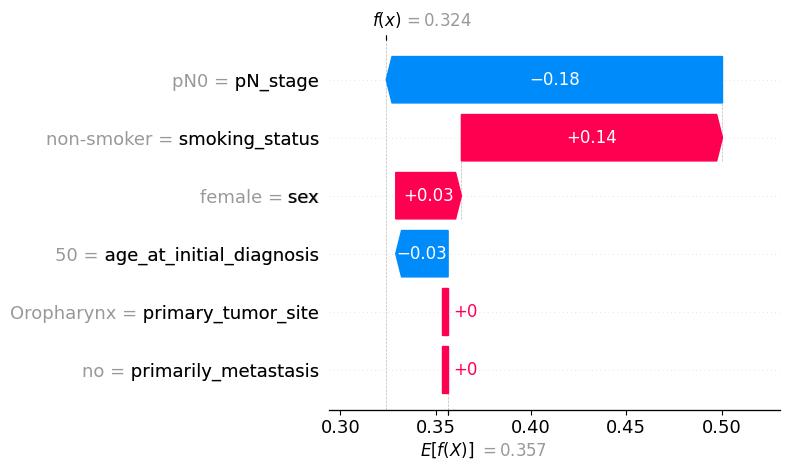

Saved: HPV_positive_SHAP_waterfall.png

Calculating LIME values...


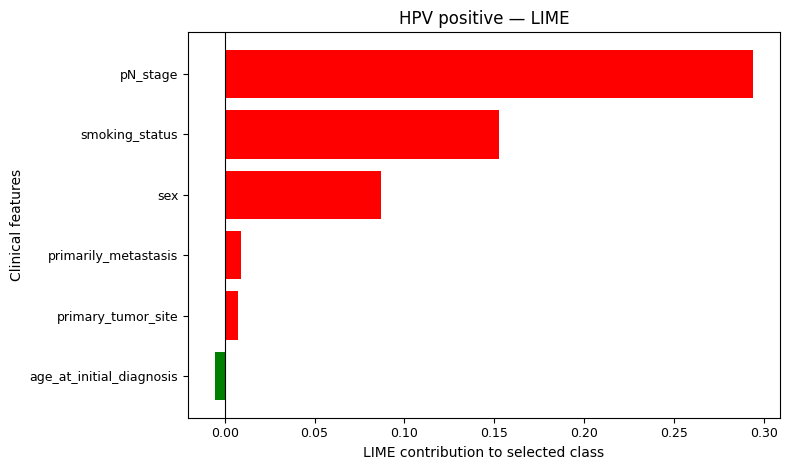

Saved: HPV_positive_LIME_bar.png

Explaining: HPV_negative
Actual class: 0
Predicted class: 0
HPV-negative probability: 0.8622
HPV-positive probability: 0.1378

Calculating SHAP values...


  0%|          | 0/1 [00:00<?, ?it/s]

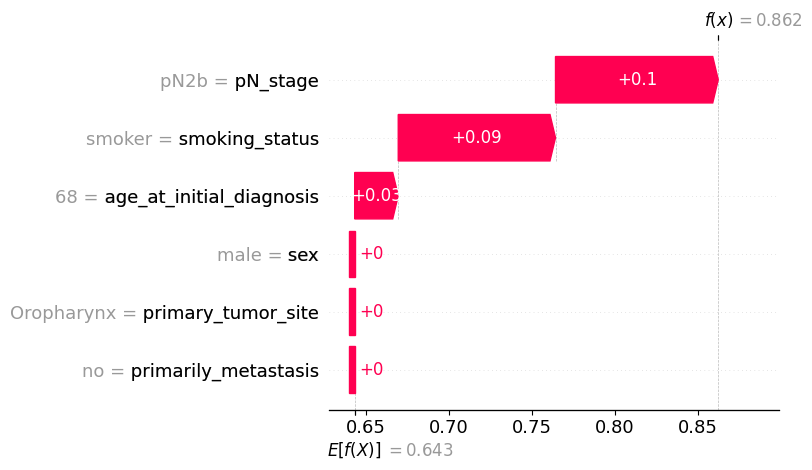

Saved: HPV_negative_SHAP_waterfall.png

Calculating LIME values...


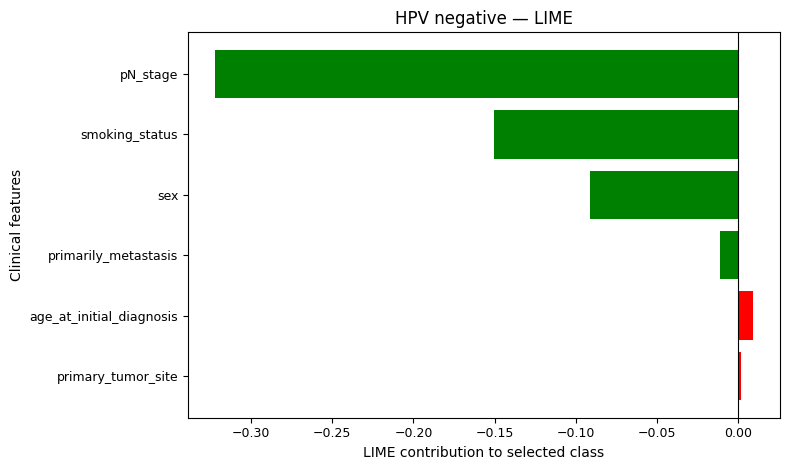

Saved: HPV_negative_LIME_bar.png

Patient prediction summary:


,patient,actual_class,predicted_class,negative_probability,positive_probability
0,HPV_positive,1,0,0.675918,0.324082
1,HPV_negative,0,0,0.862195,0.137805



Saved plot dimensions:
HPV_positive_SHAP_waterfall.png -> (2400, 1440) pixels
HPV_positive_LIME_bar.png -> (2400, 1440) pixels
HPV_negative_SHAP_waterfall.png -> (2400, 1440) pixels
HPV_negative_LIME_bar.png -> (2400, 1440) pixels

All four plots saved in:
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Individual_Patients

ZIP file:
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/SHAP_LIME_Individual_Patients/GPT2_HPV_SHAP_LIME_ALL_4_PLOTS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Completed: four plots and ZIP download requested.


In [2]:

# ============================================================
# GPT-2 TABULAR HPV CLASSIFIER
# SHAP + LIME FOR ONE ACTUAL POSITIVE AND ONE ACTUAL NEGATIVE
# Four same-size PNG plots + ZIP download
# ============================================================

!pip -q install shap lime

import os
import zipfile
import numpy as np
import pandas as pd
import torch
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import files

# ------------------------------------------------------------
# 1. CHECK NOTEBOOK VARIABLES
# ------------------------------------------------------------

required = [
    "model", "device", "X_train", "X_test",
    "y_train", "y_test", "test", "preprocessor",
    "features", "OUT_DIR", "CHECKPOINT_DIR"
]

missing = [v for v in required if v not in globals()]

if missing:
    raise NameError(
        "Run the notebook's data preparation and model sections first. "
        f"Missing variables: {missing}"
    )

# Original clinical predictors from this notebook
features = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis",
    "pN_stage"
]

# ------------------------------------------------------------
# 2. LOAD BEST VALIDATION ROC-AUC CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "gpt2_best_val_roc_auc.pt"
)

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}\n"
        "Please run the model training section first."
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Loaded best validation ROC-AUC checkpoint.")
print("Checkpoint epoch:", checkpoint["epoch"])

# ------------------------------------------------------------
# 3. CHECK ENCODED FEATURES AND MAP THEM TO ORIGINAL FEATURES
# ------------------------------------------------------------

X_train_np = np.asarray(X_train, dtype=np.float32)
X_test_np = np.asarray(X_test, dtype=np.float32)

encoded_names = list(preprocessor.get_feature_names_out())

if X_train_np.shape[1] != len(encoded_names):
    raise ValueError(
        "The encoded feature names do not match X_train dimensions."
    )

# Map every encoded column back to its original clinical predictor.
feature_groups = {}

for original_feature in features:
    matching_indices = []

    for j, encoded_name in enumerate(encoded_names):
        if (
            encoded_name == f"num__{original_feature}"
            or encoded_name == f"cat__{original_feature}"
            or encoded_name.startswith(f"cat__{original_feature}_")
        ):
            matching_indices.append(j)

    if not matching_indices:
        raise ValueError(
            f"Could not map encoded columns to {original_feature}. "
            f"Available columns: {encoded_names}"
        )

    feature_groups[original_feature] = matching_indices

print("\nOriginal-to-encoded feature mapping:")
for name, indices in feature_groups.items():
    print(f"{name}: {len(indices)} encoded column(s)")

# ------------------------------------------------------------
# 4. SELECT ONE ACTUAL POSITIVE AND ONE ACTUAL NEGATIVE
# ------------------------------------------------------------

y_test_np = np.asarray(y_test).astype(int)

positive_indices = np.where(y_test_np == 1)[0]
negative_indices = np.where(y_test_np == 0)[0]

if len(positive_indices) == 0:
    raise ValueError("No actual HPV-positive patient in the test set.")

if len(negative_indices) == 0:
    raise ValueError("No actual HPV-negative patient in the test set.")

# First actual patient of each class in the test set
positive_idx = int(positive_indices[0])
negative_idx = int(negative_indices[0])

patient_indices = {
    "HPV_positive": positive_idx,
    "HPV_negative": negative_idx
}

print("\nSelected test patients:")
print("HPV-positive index:", positive_idx)
print("HPV-negative index:", negative_idx)

if "patient_id" in test.columns:
    print("Positive patient ID:",
          test.iloc[positive_idx]["patient_id"])
    print("Negative patient ID:",
          test.iloc[negative_idx]["patient_id"])

# ------------------------------------------------------------
# 5. MODEL PREDICTION FUNCTION
# ------------------------------------------------------------

def gpt2_predict_proba(data):
    """
    Input:
        2D numpy array of preprocessed model features.

    Output:
        Two-column probabilities:
        column 0 = HPV negative
        column 1 = HPV positive
    """

    data = np.asarray(data, dtype=np.float32)

    if data.ndim == 1:
        data = data.reshape(1, -1)

    if data.shape[1] != X_train_np.shape[1]:
        raise ValueError(
            f"Expected {X_train_np.shape[1]} features, "
            f"received {data.shape[1]}."
        )

    model.eval()
    all_probabilities = []

    with torch.no_grad():
        for start in range(0, len(data), 128):

            batch = data[start:start + 128]

            tensor = torch.tensor(
                batch,
                dtype=torch.float32,
                device=device
            )

            logits = model(tensor)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            all_probabilities.append(
                probabilities.detach().cpu().numpy()
            )

    return np.vstack(all_probabilities)


# ------------------------------------------------------------
# 6. OUTPUT FOLDER
# ------------------------------------------------------------

output_dir = Path(OUT_DIR) / "SHAP_LIME_Individual_Patients"
output_dir.mkdir(parents=True, exist_ok=True)

# All four plots use exactly the same dimensions and resolution.
FIGSIZE = (8, 4.8)
DPI = 300

# ------------------------------------------------------------
# 7. SHAP BACKGROUND DATA
# ------------------------------------------------------------

rng = np.random.default_rng(42)

background_size = min(20, len(X_train_np))

background_indices = rng.choice(
    len(X_train_np),
    size=background_size,
    replace=False
)

background = X_train_np[background_indices]

print("\nSHAP background size:", len(background))

# ------------------------------------------------------------
# 8. CREATE SHAP AND LIME EXPLAINERS
# ------------------------------------------------------------

# LIME operates on the encoded input columns.
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=encoded_names,
    class_names=["HPV Negative", "HPV Positive"],
    mode="classification",
    discretize_continuous=False,
    random_state=42
)

# ------------------------------------------------------------
# 9. HELPER: GROUP ENCODED VALUES INTO SIX ORIGINAL FEATURES
# ------------------------------------------------------------

def group_encoded_values(encoded_values):
    """
    Sum encoded-column contributions belonging to each
    original clinical predictor.
    """

    encoded_values = np.asarray(encoded_values).reshape(-1)

    grouped = []

    for original_feature in features:
        indices = feature_groups[original_feature]
        grouped.append(float(np.sum(encoded_values[indices])))

    return np.asarray(grouped, dtype=float)


def get_display_values(patient_index):
    """
    Show the original clinical values for the selected patient.
    Uses the prepared test dataframe from the notebook.
    """

    row = test.iloc[patient_index]

    values = []

    for feature in features:
        value = row[feature]

        if pd.isna(value):
            value = "Unknown"

        values.append(value)

    return values


# ------------------------------------------------------------
# 10. GENERATE SHAP WATERFALL AND LIME BAR CHARTS
# ------------------------------------------------------------

def explain_patient(patient_name, patient_index, class_label):

    print("\n" + "=" * 60)
    print("Explaining:", patient_name)
    print("=" * 60)

    patient_encoded = X_test_np[
        patient_index:patient_index + 1
    ]

    probabilities = gpt2_predict_proba(patient_encoded)[0]

    predicted_class = int(np.argmax(probabilities))

    actual_class = int(y_test_np[patient_index])

    print("Actual class:", actual_class)
    print("Predicted class:", predicted_class)
    print("HPV-negative probability:", round(float(probabilities[0]), 4))
    print("HPV-positive probability:", round(float(probabilities[1]), 4))

    if actual_class != class_label:
        raise ValueError("Selected patient does not match requested class.")

    # --------------------------------------------------------
    # SHAP: EXPLAIN PROBABILITY OF THE ACTUAL CLASS
    # --------------------------------------------------------

    print("\nCalculating SHAP values...")

    def shap_prediction(data):
        return gpt2_predict_proba(data)[:, class_label]

    shap_explainer = shap.KernelExplainer(
        shap_prediction,
        background
    )

    shap_result = shap_explainer.shap_values(
        patient_encoded,
        nsamples=300
    )

    if isinstance(shap_result, list):
        shap_values_encoded = np.asarray(
            shap_result[0]
        ).reshape(-1)
    else:
        shap_values_encoded = np.asarray(
            shap_result
        )

        if shap_values_encoded.ndim == 3:
            shap_values_encoded = shap_values_encoded[0, :, class_label]
        elif shap_values_encoded.ndim == 2:
            shap_values_encoded = shap_values_encoded[0]

        shap_values_encoded = shap_values_encoded.reshape(-1)

    # Combine one-hot encoded contributions into original features.
    shap_values_grouped = group_encoded_values(
        shap_values_encoded
    )

    expected_value = shap_explainer.expected_value

    if isinstance(expected_value, (list, np.ndarray)):
        expected_value = np.asarray(expected_value).reshape(-1)[0]

    expected_value = float(expected_value)

    display_values = get_display_values(patient_index)

    shap_explanation = shap.Explanation(
        values=shap_values_grouped,
        base_values=expected_value,
        data=np.asarray(display_values, dtype=object),
        feature_names=features
    )

    shap_filename = (
        f"{patient_name}_SHAP_waterfall.png"
    )

    plt.figure(figsize=FIGSIZE)

    shap.plots.waterfall(
        shap_explanation,
        max_display=len(features),
        show=False
    )

    plt.gcf().set_size_inches(*FIGSIZE)
    plt.tight_layout()

    plt.savefig(
        output_dir / shap_filename,
        dpi=DPI,
        format="png"
    )

    plt.show()
    plt.close("all")

    print("Saved:", shap_filename)

    # --------------------------------------------------------
    # LIME: EXPLAIN PROBABILITY OF THE ACTUAL CLASS
    # --------------------------------------------------------

    print("\nCalculating LIME values...")

    lime_explanation = lime_explainer.explain_instance(
        data_row=patient_encoded[0],
        predict_fn=gpt2_predict_proba,
        labels=(class_label,),
        num_features=len(encoded_names),
        num_samples=1500
    )

    # Retrieve contributions for the actual class.
    lime_encoded_weights = np.zeros(
        len(encoded_names),
        dtype=float
    )

    for feature_index, contribution in lime_explanation.as_map()[
        class_label
    ]:
        lime_encoded_weights[feature_index] = contribution

    # Group encoded contributions into original predictors.
    lime_grouped_weights = group_encoded_values(
        lime_encoded_weights
    )

    # Sort by absolute contribution.
    order = np.argsort(
        np.abs(lime_grouped_weights)
    )

    sorted_features = [
        features[i] for i in order
    ]

    sorted_weights = lime_grouped_weights[order]

    # Red = contribution toward the selected class.
    # Green = contribution away from the selected class.
    bar_colours = [
        "red" if value > 0 else "green"
        for value in sorted_weights
    ]

    lime_filename = (
        f"{patient_name}_LIME_bar.png"
    )

    plt.figure(figsize=FIGSIZE)

    plt.barh(
        sorted_features,
        sorted_weights,
        color=bar_colours
    )

    plt.axvline(
        0,
        color="black",
        linewidth=0.8
    )

    plt.xlabel(
        "LIME contribution to selected class"
    )

    plt.ylabel("Clinical features")

    plt.title(
        f"{patient_name.replace('_', ' ')} — LIME"
    )

    plt.yticks(fontsize=9)
    plt.xticks(fontsize=9)

    plt.gcf().set_size_inches(*FIGSIZE)
    plt.tight_layout()

    plt.savefig(
        output_dir / lime_filename,
        dpi=DPI,
        format="png"
    )

    plt.show()
    plt.close("all")

    print("Saved:", lime_filename)

    return {
        "patient": patient_name,
        "actual_class": actual_class,
        "predicted_class": predicted_class,
        "negative_probability": float(probabilities[0]),
        "positive_probability": float(probabilities[1])
    }


# ------------------------------------------------------------
# 11. EXPLAIN ONE ACTUAL POSITIVE AND ONE ACTUAL NEGATIVE
# ------------------------------------------------------------

positive_results = explain_patient(
    patient_name="HPV_positive",
    patient_index=positive_idx,
    class_label=1
)

negative_results = explain_patient(
    patient_name="HPV_negative",
    patient_index=negative_idx,
    class_label=0
)

# ------------------------------------------------------------
# 12. SAVE PATIENT PREDICTION SUMMARY
# ------------------------------------------------------------

summary_df = pd.DataFrame([
    positive_results,
    negative_results
])

summary_path = output_dir / "patient_prediction_summary.csv"

summary_df.to_csv(
    summary_path,
    index=False
)

print("\nPatient prediction summary:")
display(summary_df)

# ------------------------------------------------------------
# 13. CREATE ZIP FILE WITH ALL FOUR PLOTS
# ------------------------------------------------------------

plot_files = [
    output_dir / "HPV_positive_SHAP_waterfall.png",
    output_dir / "HPV_positive_LIME_bar.png",
    output_dir / "HPV_negative_SHAP_waterfall.png",
    output_dir / "HPV_negative_LIME_bar.png"
]

zip_path = output_dir / "GPT2_HPV_SHAP_LIME_ALL_4_PLOTS.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file_path in plot_files:
        if not file_path.exists():
            raise FileNotFoundError(
                f"Expected plot was not created: {file_path}"
            )

        zipf.write(
            file_path,
            arcname=file_path.name
        )

# ------------------------------------------------------------
# 14. VERIFY PLOT DIMENSIONS
# ------------------------------------------------------------

from PIL import Image

print("\nSaved plot dimensions:")

for file_path in plot_files:
    with Image.open(file_path) as img:
        print(
            file_path.name,
            "->",
            img.size,
            "pixels"
        )

print("\nAll four plots saved in:")
print(output_dir)

print("\nZIP file:")
print(zip_path)

# ------------------------------------------------------------
# 15. AUTOMATICALLY DOWNLOAD ZIP
# ------------------------------------------------------------

files.download(str(zip_path))

print("\nCompleted: four plots and ZIP download requested.")
